# H2. Список к походу — результаты

## Сокращения, аббревиатуры и метрики

| Как написано | Расшифровка |
|---|---|
| **H2** | гипотеза 2 этой предзащиты: список к походу. |
| **десятка**, top-10 | первые 10 продуктов в отсортированном списке кандидатов. |
| **Recall@10** | полнота десятки. Сколько купленного в *следующем* походе попало в десятку, делённое на размер этой корзины. Среднее по походам. Лишние советы число не уменьшают. Главная метрика H2. |
| **HitRate@10** | доля походов, где в десятку попал *хотя бы один* купленный продукт. Грубее Recall@10: не смотрит, сколько угадали. |
| **PR-AUC** | Precision–Recall Area Under Curve, площадь под кривой точность–полнота. Считается по вероятности «будет в следующей корзине» на всех позициях, не только на десятке. |
| **CatBoost** | Categorical Boosting: градиентный бустинг на решающих деревьях с категориями (код продукта, категория, тип семьи). Статья: Prokhorenkova et al., NeurIPS 2018. |
| **нейросеть**, MLP | многослойный перцептрон. В таблице этапа 7 — соседняя постановка, не вариант вердикта H2. |
| **обычно берут**, `pair_visit_share` | доля походов семьи, в которых продукт уже брали: (число таких походов) / (число походов семьи к этому моменту). Правило сравнения H2. |
| **split** | разрез данных по времени: train — учёба, validation — ранняя остановка, test — вердикт. |
| **Ta Feng** | открытые тайваньские чеки 2000–2001. Остатка холодильника нет. Отрицательный контроль H2. |
| **SQLite**, `fridge_lab` | учебная база синтетических семей с остатком и планом похода. Файл прогона — `fridge_lab_v2.sqlite`. |
| **CSV** | таблица уже посчитанных метрик. Ноутбук её только читает. |

Гипотеза: модель, которая видит **остаток, расход и срок**, собирает десятку к следующему походу лучше правила «обычно берут» не меньше чем на **0,10 Recall@10**.

Ноутбук **не учит** CatBoost. Он показывает уже посчитанные таблицы и картинки из папок `результаты/` и `данные/метрики/`. Повтор прогона — `код/check_main_v2.py` на `fridge_lab_v2.sqlite`.

Порядок этапов:
1. пути и сводная таблица порога;
2. официальный результат 200 / 500 семей;
3. те же походы, простые правила;
4. пример одной десятки;
5. разброс по семьям;
6. запас как шумный вход;
7. полная таблица теста и что стоит в столбце «Модель».

## Этап 1. Пути и сводная таблица порога

Читаем `результаты/recall10.csv`. Строка — одна база, не один поход.

- **обычно_берут** — сортировка кандидатов по доле походов семьи с продуктом (`pair_visit_share`).
- **модель** — CatBoost на истории, остатке, расходе, сроке и днях до похода.
- **прирост** — разница Recall@10. Порог 0,10 записан до теста и здесь не двигается.

Ta Feng — чужие чеки **без остатка**. Там порог не взят: без холодильника гипотеза на продукт не переносится.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# Запускать из папки Артефакты/, где лежат результаты/ и данные/.
HERE = Path.cwd()
if not (HERE / "результаты").is_dir():
    HERE = Path(".").resolve()
RESULTS = HERE / "результаты"
DATA = HERE / "данные" / "метрики"

# Официальный вердикт H2: две учебные базы и отрицательный контроль без запаса.
pd.read_csv(RESULTS / "recall10.csv")

база,походов,обычно_берут,модель,прирост,порог,вердикт
200 семей,2807,0.494,0.631,0.137,0.1,подтверждена
500 семей семя 43,6646,0.496,0.648,0.152,0.1,подтверждена
Ta Feng чеки без остатка,17062,NaN,,0.070,0.1,не подтверждена


## Этап 2. Официальный результат на учебной базе

Слева частота («обычно берут»), справа модель с остатком. Над столбиками — прирост.

200 семей, 2 807 походов: 0,494 → 0,631, **+0,137**. Повтор 500 семей, семя генератора 43, 6 646 походов: 0,496 → 0,648, **+0,152**. Оба раза порог 0,10 взят. Учёба до 1 июня 2026, тест 1 августа — 16 сентября, прогноз через 3 часа после уже сделанного похода.

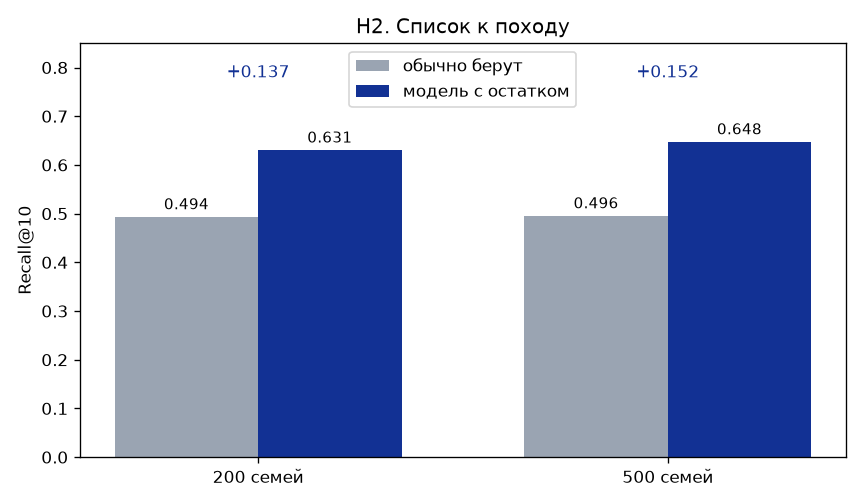

In [2]:
# Сводка для защиты: две учебные базы, один порог.
display(Image(str(RESULTS / 'recall10_сравнение.png'), width=720))

## Этап 3. Те же походы, разные правила

На тесте 200 семей частота — лучшее **простое** правило (Recall@10 ≈ 0,494). Личный интервал и запас в приложении слабее. Правило «привычный и кончается» лучше чистого запаса, но до частоты не дотягивает (≈ 0,447).

Модель на тех же кандидатах даёт ≈ 0,631. Значит выигрыш не от «просто посмотреть остаток», а от совместных признаков. Картинка строится из `данные/метрики/forecast_v1_metrics.csv`, split = test.

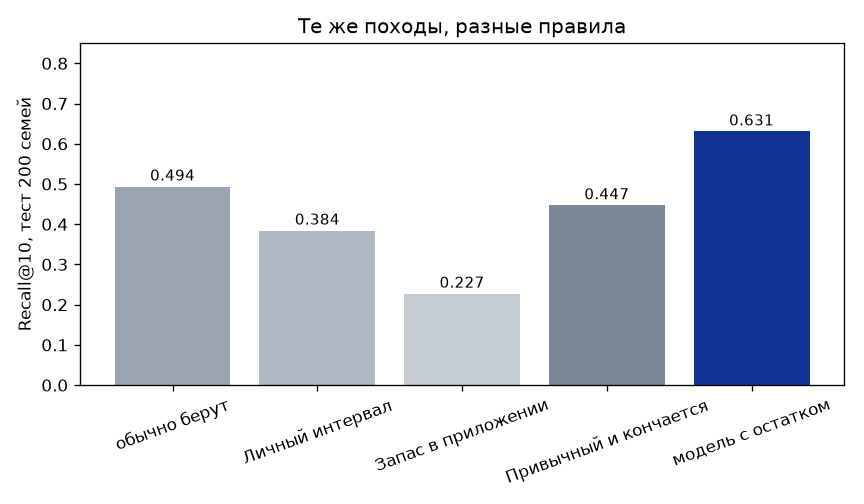

In [3]:
# Контроль: частота, интервал, запас, «привычный и кончается», CatBoost.
display(Image(str(RESULTS / 'recall10_правила_тест.png'), width=720))

## Этап 4. Пример одной десятки

Один поход одной семьи. Кандидаты отсортированы моделью сверху вниз. Зелёное — продукт реально купили в следующем походе, серое — нет. Черта отсекает топ-10: в Recall@10 входят только зелёные выше черты.

Так видно, за счёт чего растёт метрика: в десятку попадает то, что кончается, а вчерашнее молоко с запасом уходит ниже.

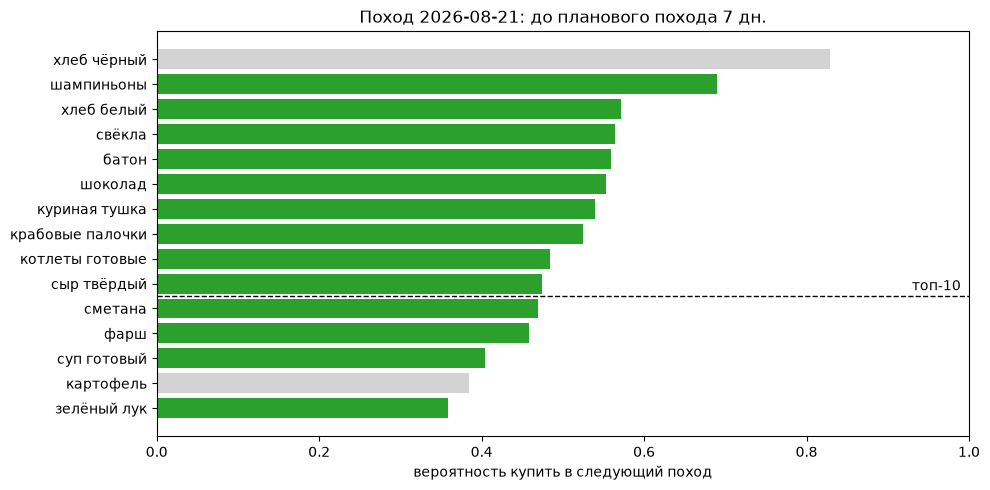

In [4]:
# Пример списка: зелёное купили, серое нет, черта — граница десятки.
display(Image(str(RESULTS / 'shopping_list.png'), width=720))

## Этап 5. Устойчивость по семьям

Единица порога — поход, но разброс смотрим по семьям: среднее Recall@10 модели внутри семьи. Медиана около 0,62, типичный размах примерно 0,37…0,94.

Гипотеза не «всем одинаково +0,14», а «в среднем по походам порог взят». Хвост слева — семьи, где десятка всё ещё слабая.

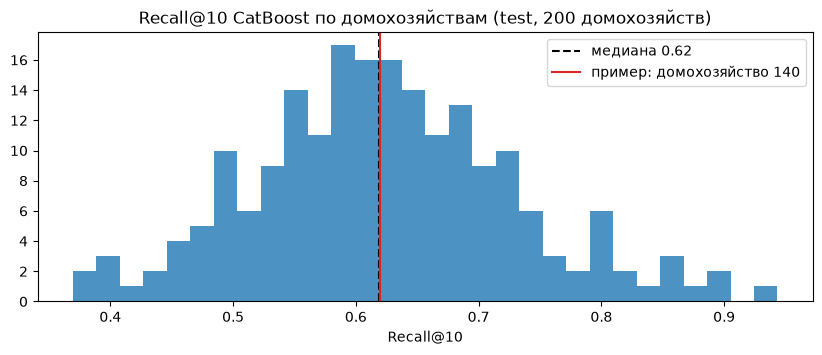

In [5]:
# Распределение Recall@10 модели по семьям, не по походам.
display(Image(str(RESULTS / 'household_recall.png'), width=720))

## Этап 6. Запас — вход модели, не правда холодильника

Остаток в приложении шумит: пользователь отмечает покупку не сразу, списание идёт грубым правилом. На этапе 3 одно это правило проигрывает частоте.

В модель запас всё равно входит вместе с историей, расходом и сроком. График — иллюстрация входа, не доказательство, что учёт «идеальный».

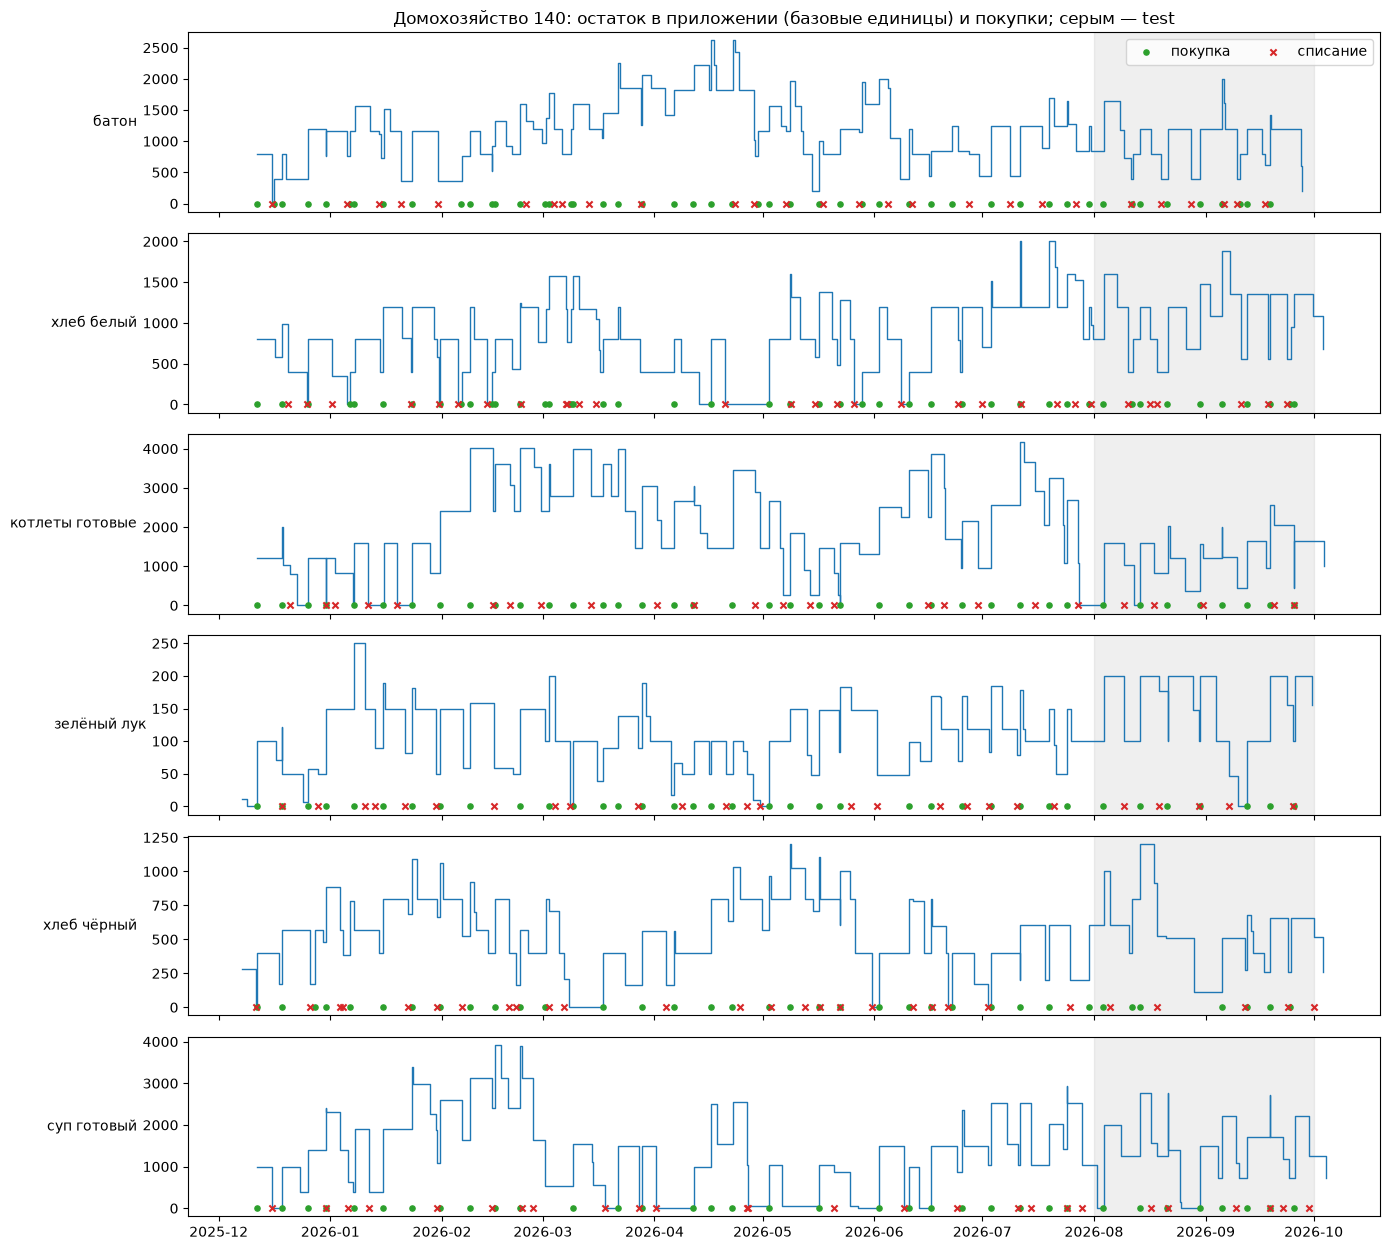

In [6]:
# Шумный ряд остатка: вход признака, не эталон холодильника.
display(Image(str(RESULTS / 'stock_timeline.png'), width=720))

## Этап 7. Полная таблица теста, 200 семей

Те же походы, что на этапе 3. Столбец **Модель** — способ отсортировать один и тот же список кандидатов (продукты семьи за 60 дней). HitRate@10 высокий почти у всех: в десятку хоть что-то из корзины попадает часто. Различает методы Recall@10. PR-AUC смотрит вероятности по всем позициям.

### Что в столбце «Модель»

Первые пять строк — **правила без обучения**. Дальше — обученные модели из того же прогона `forecast_v1_metrics.csv`.

| Строка | Что это |
|---|---|
| **Доля походов с продуктом** | Правило «обычно берут»: `pair_visit_share`. База H2. Recall@10 ≈ 0,494. |
| **Личный интервал** | Сколько дней осталось до обычного перерыва этой пары (средний интервал минус дни с последней покупки). Чем меньше осталось, тем выше в списке. |
| **Запас в приложении** | На сколько дней хватит остатка при расходе за 30 дней. Чем меньше запас, тем выше. |
| **Запас к походу** | Запас в днях минус дни до планового похода: «кончится до похода — купить». |
| **Привычный и кончается** | «Запас к походу», но продукты с меньше чем тремя покупками уходят в конец. |
| **CatBoost: след. поход** | **Вариант гипотезы H2.** Один CatBoost, метка «продукт будет в *следующей* корзине» (`in_next_basket`). Признаки: история пары, остаток, расход, срок, дни до похода; категории — продукт, категория, тип семьи. Сортирует тех же кандидатов, что и правило частоты. Recall@10 ≈ 0,631, прирост ≈ +0,137. Порог 0,10 берётся с этой строки. |
| **CatBoost: 14 дней** | Тот же бустинг и те же признаки, но метка другая: «купят в ближайшие 14 дней», не «в следующем походе». Список к походу у неё хуже (≈ 0,585). В вердикт H2 не входит. |
| **Нейросеть: 14 дней** | Многослойный перцептрон (два скрытых слоя), вероятность покупки за 14 дней. Соседняя постановка, не H2. |
| **Нейросеть: к дате похода** | Та же сеть, вероятность к дате планового похода. Recall@10 близкий к H2 (≈ 0,635), PR-AUC ниже, чем у «CatBoost: след. поход». Порог H2 на неё не опирается. |

Итог по столбцу: для H2 сравнивают только **Доля походов с продуктом** и **CatBoost: след. поход**. Остальные строки показывают, что выигрыш не от «просто посмотреть остаток» и не от любой модели с любой меткой.

In [7]:
# Только тест. Валидация в том же csv, в вердикт H2 не входит.
metrics = pd.read_csv(DATA / "forecast_v1_metrics.csv")
metrics[metrics["split"] == "test"][
    ["Модель", "Recall@10", "HitRate@10", "PR-AUC след. поход"]
]

Модель,Recall@10,HitRate@10,PR-AUC след. поход
Доля походов с продуктом,0.493614,0.933979,0.593119
Личный интервал,0.384045,0.924650,0.390621
Запас в приложении,0.227344,0.740940,0.306777
Запас к походу,0.228045,0.745246,0.303846
Привычный и кончается,0.447093,0.911374,0.478751
CatBoost: след. поход,0.630670,0.987442,0.707538
CatBoost: 14 дней,0.585491,0.975242,0.600333
Нейросеть: 14 дней,0.622362,0.987442,0.624508
Нейросеть: к дате похода,0.635412,0.988159,0.653180
